In [2]:
from pathlib import Path

data_path = Path("../data/raw")

print("Files available:")
for file in data_path.iterdir():
    print(file.name)

Files available:
calendar.csv
sales_train_evaluation.csv
sales_train_validation.csv
sample_submission.csv
sell_prices.csv


In [3]:
import pandas as pd
import numpy as np


In [4]:
calendar_df = pd.read_csv("C:\\Users\\Admin\\OneDrive\\Desktop\\SalesPulse-AI\\data\\raw\\calendar.csv")

print("Dataset loaded successfully!")
print("Shape:", calendar_df.shape)

Dataset loaded successfully!
Shape: (1969, 14)


In [5]:
calendar_df.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [6]:
calendar_df.tail()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
1964,2016-06-15,11620,Wednesday,5,6,2016,d_1965,NaN,NaN,NaN,NaN,0,1,1
1965,2016-06-16,11620,Thursday,6,6,2016,d_1966,NaN,NaN,NaN,NaN,0,0,0
1966,2016-06-17,11620,Friday,7,6,2016,d_1967,NaN,NaN,NaN,NaN,0,0,0
1967,2016-06-18,11621,Saturday,1,6,2016,d_1968,NaN,NaN,NaN,NaN,0,0,0
1968,2016-06-19,11621,Sunday,2,6,2016,d_1969,NBAFinalsEnd,Sporting,Father's day,Cultural,0,0,0


In [7]:
calendar_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   date          1969 non-null   str  
 1   wm_yr_wk      1969 non-null   int64
 2   weekday       1969 non-null   str  
 3   wday          1969 non-null   int64
 4   month         1969 non-null   int64
 5   year          1969 non-null   int64
 6   d             1969 non-null   str  
 7   event_name_1  162 non-null    str  
 8   event_type_1  162 non-null    str  
 9   event_name_2  5 non-null      str  
 10  event_type_2  5 non-null      str  
 11  snap_CA       1969 non-null   int64
 12  snap_TX       1969 non-null   int64
 13  snap_WI       1969 non-null   int64
dtypes: int64(7), str(7)
memory usage: 263.1 KB


In [8]:
calendar_df.isna().sum()

date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

In [9]:
print(calendar_df.shape)

print(calendar_df.columns.tolist())

print(calendar_df.head())   

print(calendar_df.isnull().sum())

(1969, 14)
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
         date  wm_yr_wk    weekday  wday  month  year    d event_name_1  \
0  2011-01-29     11101   Saturday     1      1  2011  d_1          NaN   
1  2011-01-30     11101     Sunday     2      1  2011  d_2          NaN   
2  2011-01-31     11101     Monday     3      1  2011  d_3          NaN   
3  2011-02-01     11101    Tuesday     4      2  2011  d_4          NaN   
4  2011-02-02     11101  Wednesday     5      2  2011  d_5          NaN   

  event_type_1 event_name_2 event_type_2  snap_CA  snap_TX  snap_WI  
0          NaN          NaN          NaN        0        0        0  
1          NaN          NaN          NaN        0        0        0  
2          NaN          NaN          NaN        0        0        0  
3          NaN          NaN          NaN        1        1        0  
4          NaN          NaN  

In [10]:
calendar_df["date_converted"]=pd.to_datetime(calendar_df["date"],errors="coerce")
print("invalid date values:",calendar_df["date_converted"].isnull().sum())

invalid date values: 0


In [11]:
print("Minimum date:", calendar_df["date_converted"].min())
print("Maximum date:", calendar_df["date_converted"].max())

Minimum date: 2011-01-29 00:00:00
Maximum date: 2016-06-19 00:00:00


In [12]:
print("Duplicate dates:", calendar_df["date"].duplicated().sum())
print("Unique dates:", calendar_df["date"].nunique())

Duplicate dates: 0
Unique dates: 1969


In [13]:
print("Duplicate day identifiers:", calendar_df["d"].duplicated().sum())
print("Unique day identifiers:", calendar_df["d"].nunique())

Duplicate day identifiers: 0
Unique day identifiers: 1969


In [14]:
from pathlib import Path

sales_file = Path("C:/Users/Admin/OneDrive/Desktop/SalesPulse-AI/data/raw/sales_train_validation.csv")

print("File exists:",sales_file.exists())
print("File path:", sales_file)
    

File exists: True
File path: C:\Users\Admin\OneDrive\Desktop\SalesPulse-AI\data\raw\sales_train_validation.csv


In [15]:
sales_columns = pd.read_csv(sales_file,nrows=0).columns.tolist()

print("Number of columns:", len(sales_columns))
print("\nColumn names:")
print(sales_columns)


Number of columns: 1919

Column names:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10', 'd_11', 'd_12', 'd_13', 'd_14', 'd_15', 'd_16', 'd_17', 'd_18', 'd_19', 'd_20', 'd_21', 'd_22', 'd_23', 'd_24', 'd_25', 'd_26', 'd_27', 'd_28', 'd_29', 'd_30', 'd_31', 'd_32', 'd_33', 'd_34', 'd_35', 'd_36', 'd_37', 'd_38', 'd_39', 'd_40', 'd_41', 'd_42', 'd_43', 'd_44', 'd_45', 'd_46', 'd_47', 'd_48', 'd_49', 'd_50', 'd_51', 'd_52', 'd_53', 'd_54', 'd_55', 'd_56', 'd_57', 'd_58', 'd_59', 'd_60', 'd_61', 'd_62', 'd_63', 'd_64', 'd_65', 'd_66', 'd_67', 'd_68', 'd_69', 'd_70', 'd_71', 'd_72', 'd_73', 'd_74', 'd_75', 'd_76', 'd_77', 'd_78', 'd_79', 'd_80', 'd_81', 'd_82', 'd_83', 'd_84', 'd_85', 'd_86', 'd_87', 'd_88', 'd_89', 'd_90', 'd_91', 'd_92', 'd_93', 'd_94', 'd_95', 'd_96', 'd_97', 'd_98', 'd_99', 'd_100', 'd_101', 'd_102', 'd_103', 'd_104', 'd_105', 'd_106', 'd_107', 'd_108', 'd_109', 'd_110', 'd_111', 'd_112'

In [16]:
sales_sample=pd.read_csv(sales_file,nrows=5)
print("Sample data:", sales_sample)

Sample data:                               id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  ...  d_1904  d_1905  d_1906  d_1907  d_1908  \
0       CA    0    0    0    0  ...       1       3       0       1       1   
1       CA    0    0    0    0  ...       0       0       0       0       0   
2       CA    0    0    0    0  ...       2       1       2       1       1   
3       CA    0    0    0    0  ...       1       0       5       4       1   
4       CA    0    0    0    0  ...       2       1       1       0       1   

   d_1909  d_1910  d_1911  d_19

In [17]:
daily_sales_columns=[col for col in sales_columns 
                     if col.startswith("d_")]

print("Number of daily sales columns:", len(daily_sales_columns))
print("First 5 daily columns:", daily_sales_columns[:5])
print("Last 5 daily columns:", daily_sales_columns[-5:])

Number of daily sales columns: 1913
First 5 daily columns: ['d_1', 'd_2', 'd_3', 'd_4', 'd_5']
Last 5 daily columns: ['d_1909', 'd_1910', 'd_1911', 'd_1912', 'd_1913']


In [18]:
sales_sample.head(5)

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


In [19]:
sales_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Columns: 1919 entries, id to d_1913
dtypes: int64(1913), str(6)
memory usage: 75.4 KB


In [20]:
print("Unique items:", sales_sample["item_id"].nunique())
print("Unique departments:", sales_sample["dept_id"].nunique())
print("Unique categories:", sales_sample["cat_id"].nunique())
print("Unique stores:", sales_sample["store_id"].nunique())
print("Unique states:", sales_sample["state_id"].nunique())

Unique items: 5
Unique departments: 1
Unique categories: 1
Unique stores: 1
Unique states: 1


In [21]:
sales_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Columns: 1919 entries, id to d_1913
dtypes: int64(1913), str(6)
memory usage: 75.4 KB


In [22]:
sales_id_only = pd.read_csv(sales_file,usecols=["id"])
sales_id_only.head()

,id
0,HOBBIES_1_001_CA_1_validation
1,HOBBIES_1_002_CA_1_validation
2,HOBBIES_1_003_CA_1_validation
3,HOBBIES_1_004_CA_1_validation
4,HOBBIES_1_005_CA_1_validation


In [23]:
print("Total product-store records:", len(sales_id_only))
print("Duplicate IDs:", sales_id_only["id"].duplicated().sum())

Total product-store records: 30490
Duplicate IDs: 0


In [24]:
id_columns = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

sales_ids = pd.read_csv(
    sales_file,
    usecols=id_columns
)

print("Unique products:", sales_ids["item_id"].nunique())
print("Unique departments:", sales_ids["dept_id"].nunique())
print("Unique categories:", sales_ids["cat_id"].nunique())
print("Unique stores:", sales_ids["store_id"].nunique())
print("Unique states:", sales_ids["state_id"].nunique())

Unique products: 3049
Unique departments: 7
Unique categories: 3
Unique stores: 10
Unique states: 3


In [25]:
sales_ids.info()

<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   item_id   30490 non-null  str  
 1   dept_id   30490 non-null  str  
 2   cat_id    30490 non-null  str  
 3   store_id  30490 non-null  str  
 4   state_id  30490 non-null  str  
dtypes: str(5)
memory usage: 2.2 MB


In [26]:
daily_sales = pd.read_csv(
    sales_file,
    usecols=daily_sales_columns
)

print("Total missing sales values:", daily_sales.isnull().sum().sum())

Total missing sales values: 0


In [27]:
print("Negative sales values:" , (daily_sales < 0).sum().sum()) 

Negative sales values: 0


In [28]:
zero_sales = (daily_sales == 0).sum().sum()

print("Total zero-sales values:", zero_sales)

Total zero-sales values: 39777094


In [29]:
print("Minimum sales:", daily_sales.min().min())
print("Maximum sales:", daily_sales.max().max())
print("Average sales:", daily_sales.mean().mean())

Minimum sales: 0
Maximum sales: 763
Average sales: 1.126322153733316


In [30]:
total_sales_values = daily_sales.size

zero_sales_percentage = (
    zero_sales / total_sales_values
) * 100

print("Total sales observations:", total_sales_values)
print("Zero-sales observations:", zero_sales)
print("Zero-sales percentage:", round(zero_sales_percentage, 2), "%")

Total sales observations: 58327370
Zero-sales observations: 39777094
Zero-sales percentage: 68.2 %


In [31]:
non_zero_sales = daily_sales[daily_sales > 0]

print("Non-zero sales observations:", non_zero_sales.count().sum())
print("Minimum non-zero sales:", non_zero_sales.min().min())
print("Maximum non-zero sales:", non_zero_sales.max().max())
print("Average non-zero sales:", non_zero_sales.mean().mean())

Non-zero sales observations: 18550276
Minimum non-zero sales: 1.0
Maximum non-zero sales: 763.0
Average non-zero sales: 3.569874701193107


In [32]:
sales_values = daily_sales.values.flatten()

percentiles = [50, 75, 90, 95, 99, 99.5, 99.9]

print("Sales Percentiles:")

for p in percentiles:
    print(f"{p}th percentile:", np.percentile(sales_values, p))

Sales Percentiles:
50th percentile: 0.0
75th percentile: 1.0
90th percentile: 3.0
95th percentile: 5.0
99th percentile: 15.0
99.5th percentile: 22.0
99.9th percentile: 47.0


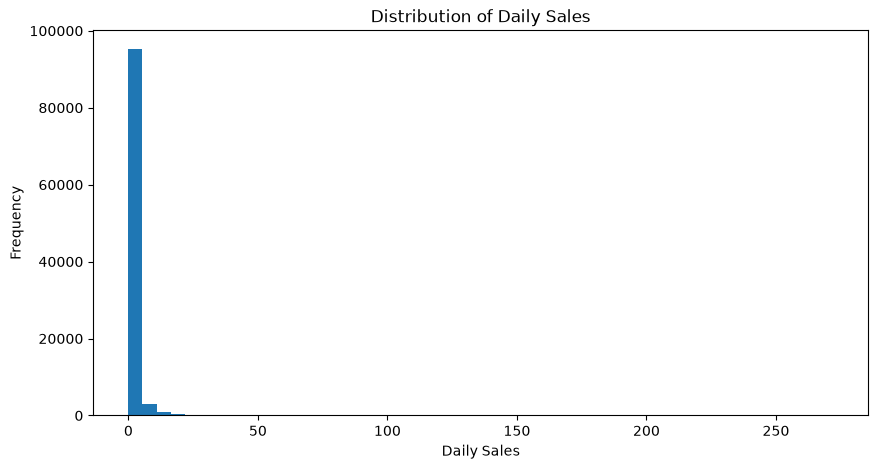

In [33]:
import matplotlib.pyplot as plt

# Take a random sample for visualization
sales_sample_values = daily_sales.values.flatten()

sample_size = 100000

rng = np.random.default_rng(42)

sample_values = rng.choice(
    sales_sample_values,
    size=sample_size,
    replace=False
)

plt.figure(figsize=(10, 5))

plt.hist(sample_values, bins=50)

plt.xlabel("Daily Sales")
plt.ylabel("Frequency")
plt.title("Distribution of Daily Sales")

plt.show()

In [34]:
q1 = np.percentile(sales_values, 25)
q3 = np.percentile(sales_values, 75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 0.0
Q3: 1.0
IQR: 1.0
Lower bound: -1.5
Upper bound: 2.5


In [35]:
# Remove zero-sales observations for outlier analysis
non_zero_values = sales_values[sales_values > 0]

q1_nonzero = np.percentile(non_zero_values, 25)
q3_nonzero = np.percentile(non_zero_values, 75)

iqr_nonzero = q3_nonzero - q1_nonzero

lower_bound_nonzero = q1_nonzero - 1.5 * iqr_nonzero
upper_bound_nonzero = q3_nonzero + 1.5 * iqr_nonzero

print("Non-zero sales IQR analysis")
print("Q1:", q1_nonzero)
print("Q3:", q3_nonzero)
print("IQR:", iqr_nonzero)
print("Lower bound:", lower_bound_nonzero)
print("Upper bound:", upper_bound_nonzero)

Non-zero sales IQR analysis
Q1: 1.0
Q3: 4.0
IQR: 3.0
Lower bound: -3.5
Upper bound: 8.5


In [36]:
outlier_count = (non_zero_values > upper_bound_nonzero).sum()

total_non_zero = len(non_zero_values)

outlier_percentage = (
    outlier_count / total_non_zero
) * 100

print("Non-zero sales above upper bound:", outlier_count)
print("Total non-zero sales:", total_non_zero)
print("Percentage of non-zero sales above upper bound:",
      round(outlier_percentage, 2), "%")

Non-zero sales above upper bound: 1452876
Total non-zero sales: 18550276
Percentage of non-zero sales above upper bound: 7.83 %


In [37]:
high_sales = non_zero_values[non_zero_values > upper_bound_nonzero]

print("Minimum high-sales value:", high_sales.min())
print("Maximum high-sales value:", high_sales.max())
print("Average high-sales value:", high_sales.mean())

Minimum high-sales value: 9
Maximum high-sales value: 763
Average high-sales value: 17.983144466561495


In [38]:
print("9–20 units:",
      ((high_sales >= 9) & (high_sales <= 20)).sum())

print("21–50 units:",
      ((high_sales >= 21) & (high_sales <= 50)).sum())

print("51–100 units:",
      ((high_sales >= 51) & (high_sales <= 100)).sum())

print("101–200 units:",
      ((high_sales >= 101) & (high_sales <= 200)).sum())

print("Above 200 units:",
      (high_sales > 200).sum())

9–20 units: 1119287
21–50 units: 284985
51–100 units: 41548
101–200 units: 6316
Above 200 units: 740


In [39]:
daily_total_sales = daily_sales.sum(axis=0)

print("Number of days:", len(daily_total_sales))
print("\nFirst 10 days:")
print(daily_total_sales.head(10))

Number of days: 1913

First 10 days:
d_1     32631
d_2     31749
d_3     23783
d_4     25412
d_5     19146
d_6     29211
d_7     28010
d_8     37932
d_9     32736
d_10    25572
dtype: int64


In [40]:
calendar_df = pd.read_csv("C:\\Users\\Admin\\OneDrive\\Desktop\\SalesPulse-AI\\data\\raw\\calendar.csv")

daily_trend = pd.DataFrame({"d":daily_total_sales.index, "total_sales":daily_total_sales.values})

daily_trend = daily_trend.merge(calendar_df[["d", "date"]], on="d", how="left")

daily_trend["date"] = pd.to_datetime(daily_trend["date"], errors="coerce")

In [41]:
daily_trend

,d,total_sales,date
0,d_1,32631,2011-01-29
1,d_2,31749,2011-01-30
2,d_3,23783,2011-01-31
3,d_4,25412,2011-02-01
4,d_5,19146,2011-02-02
...,...,...,...
1908,d_1909,35343,2016-04-20
1909,d_1910,35033,2016-04-21
1910,d_1911,40517,2016-04-22
1911,d_1912,48962,2016-04-23


In [42]:
calendar_df

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1964,2016-06-15,11620,Wednesday,5,6,2016,d_1965,NaN,NaN,NaN,NaN,0,1,1
1965,2016-06-16,11620,Thursday,6,6,2016,d_1966,NaN,NaN,NaN,NaN,0,0,0
1966,2016-06-17,11620,Friday,7,6,2016,d_1967,NaN,NaN,NaN,NaN,0,0,0
1967,2016-06-18,11621,Saturday,1,6,2016,d_1968,NaN,NaN,NaN,NaN,0,0,0


In [43]:
print("Start date:", daily_trend["date"].min())
print("End date:", daily_trend["date"].max())
print("Number of days:", daily_trend["date"].nunique())

Start date: 2011-01-29 00:00:00
End date: 2016-04-24 00:00:00
Number of days: 1913


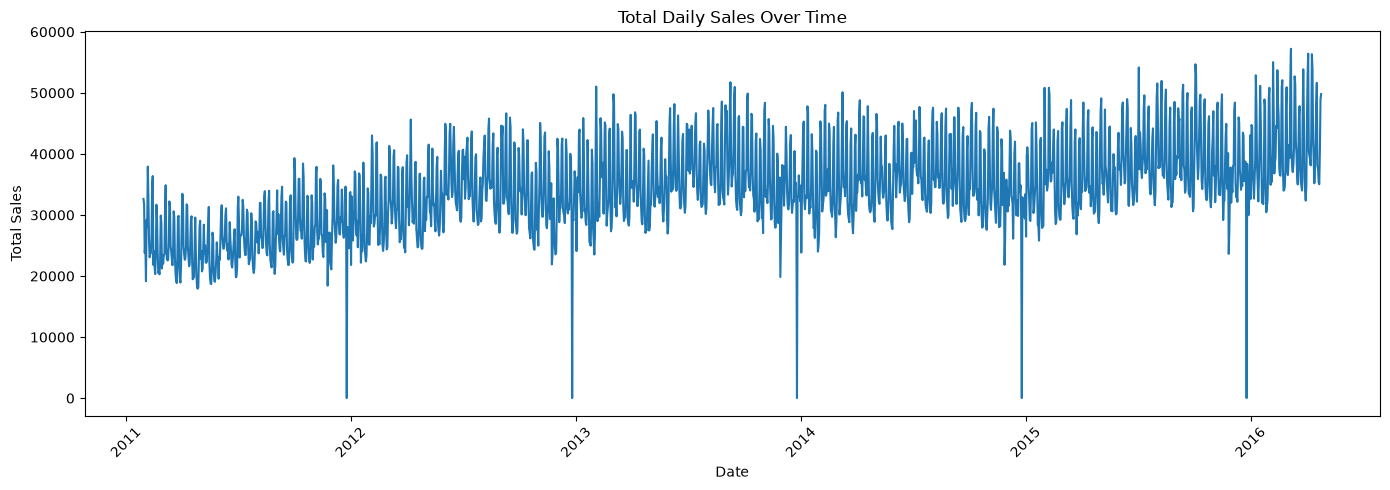

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    daily_trend["date"],
    daily_trend["total_sales"]
)

plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.title("Total Daily Sales Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
print("Minimum daily total sales:", daily_trend["total_sales"].min())

print("\nDays where total sales = 0:")
print(
    daily_trend[daily_trend["total_sales"] == 0][
        ["date", "d", "total_sales"]
    ]
)

Minimum daily total sales: 11

Days where total sales = 0:
Empty DataFrame
Columns: [date, d, total_sales]
Index: []


In [46]:
print("Number of days with zero total sales:",
      (daily_trend["total_sales"] == 0).sum())

Number of days with zero total sales: 0


In [47]:
lowest_sales_days = (
    daily_trend
    .sort_values("total_sales")
    [["date", "d", "total_sales"]]
    .head(15)
)

print(lowest_sales_days)

           date       d  total_sales
696  2012-12-25   d_697           11
330  2011-12-25   d_331           13
1791 2015-12-25  d_1792           14
1061 2013-12-25  d_1062           20
1426 2014-12-25  d_1427           20
88   2011-04-27    d_89        17929
87   2011-04-26    d_88        18113
89   2011-04-28    d_90        18145
299  2011-11-24   d_300        18427
110  2011-05-19   d_111        18684
109  2011-05-18   d_110        18770
54   2011-03-24    d_55        18854
60   2011-03-30    d_61        18928
116  2011-05-25   d_117        19058
4    2011-02-02     d_5        19146


In [48]:
lowest_dates = daily_trend.sort_values("total_sales").head(15)
calendar_df["date"] = pd.to_datetime(calendar_df["date"])
lowest_dates = lowest_dates.merge(
    calendar_df[
        ["d", "date", "event_name_1", "event_type_1",
         "event_name_2", "event_type_2"]
    ],
    on=["d", "date"],
    how="left"
)

print(lowest_dates)

         d  total_sales       date  event_name_1 event_type_1 event_name_2  \
0    d_697           11 2012-12-25     Christmas     National          NaN   
1    d_331           13 2011-12-25     Christmas     National          NaN   
2   d_1792           14 2015-12-25     Christmas     National          NaN   
3   d_1062           20 2013-12-25     Christmas     National          NaN   
4   d_1427           20 2014-12-25     Christmas     National          NaN   
5     d_89        17929 2011-04-27           NaN          NaN          NaN   
6     d_88        18113 2011-04-26    Pesach End    Religious          NaN   
7     d_90        18145 2011-04-28           NaN          NaN          NaN   
8    d_300        18427 2011-11-24  Thanksgiving     National          NaN   
9    d_111        18684 2011-05-19           NaN          NaN          NaN   
10   d_110        18770 2011-05-18           NaN          NaN          NaN   
11    d_55        18854 2011-03-24           NaN          NaN   

In [49]:
daily_trend["month"] = daily_trend["date"].dt.to_period("M")

print(daily_trend[["date", "total_sales", "month"]].head(10))

        date  total_sales    month
0 2011-01-29        32631  2011-01
1 2011-01-30        31749  2011-01
2 2011-01-31        23783  2011-01
3 2011-02-01        25412  2011-02
4 2011-02-02        19146  2011-02
5 2011-02-03        29211  2011-02
6 2011-02-04        28010  2011-02
7 2011-02-05        37932  2011-02
8 2011-02-06        32736  2011-02
9 2011-02-07        25572  2011-02


In [50]:
monthly_sales = (daily_trend.groupby("month")["total_sales"].sum())    

In [51]:
monthly_sales

month
2011-01      88163
2011-02     726375
2011-03     763567
2011-04     737713
2011-05     719562
            ...   
2015-12    1126236
2016-01    1215286
2016-02    1212927
2016-03    1275746
2016-04    1046688
Freq: M, Name: total_sales, Length: 64, dtype: int64

In [52]:
print("Number of months:", len(monthly_sales))

Number of months: 64


In [53]:
print("\nHighest monthly sales:")
print(monthly_sales.sort_values(ascending=False).head(10))    


Highest monthly sales:
month
2016-03    1275746
2015-08    1254341
2015-10    1248437
2015-07    1232147
2016-01    1215286
2016-02    1212927
2013-08    1204813
2015-09    1188913
2014-08    1184102
2013-09    1166515
Freq: M, Name: total_sales, dtype: int64


In [54]:
print("\nHighest monthly sales:")
print(monthly_sales.sort_values(ascending=True).head(10))


Highest monthly sales:
month
2011-01     88163
2011-05    719562
2011-02    726375
2011-04    737713
2011-06    753380
2011-03    763567
2011-09    813683
2011-07    819820
2011-11    823087
2011-08    825694
Freq: M, Name: total_sales, dtype: int64


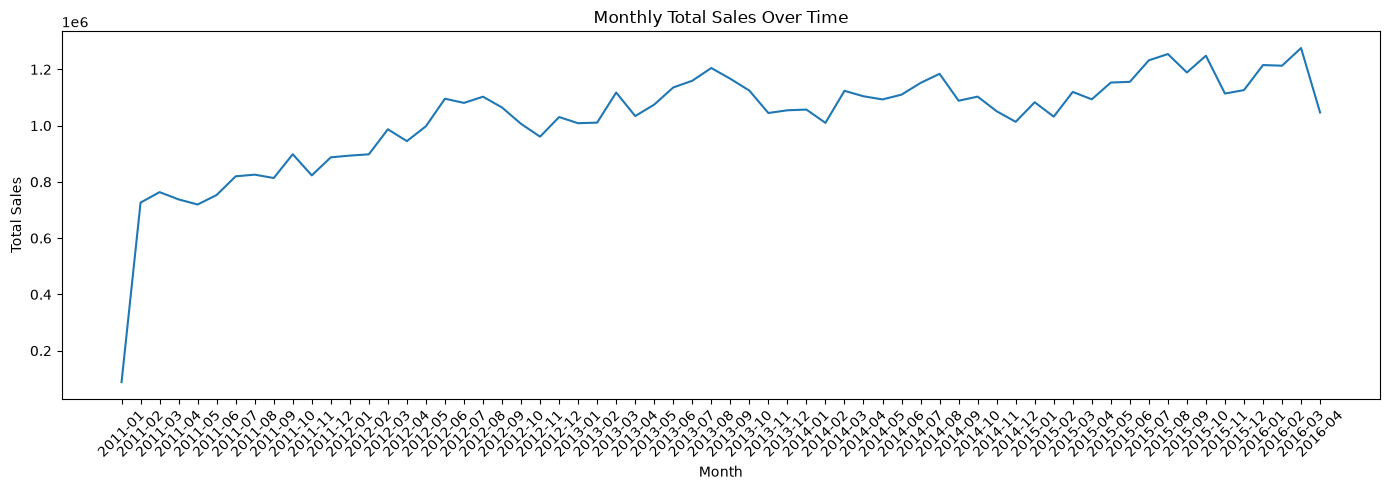

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Total Sales Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [56]:
monthly_pattern = (
    daily_trend
    .assign(month_number=daily_trend["date"].dt.month)
    .groupby("month_number")["total_sales"]
    .mean()
)

print(monthly_pattern)

month_number
1     33832.348101
2     34644.641176
3     34339.838710
4     34258.683908
5     32503.851613
6     35001.413333
7     35122.419355
8     35946.645161
9     35479.260000
10    34713.477419
11    33290.826667
12    32980.464516
Name: total_sales, dtype: float64


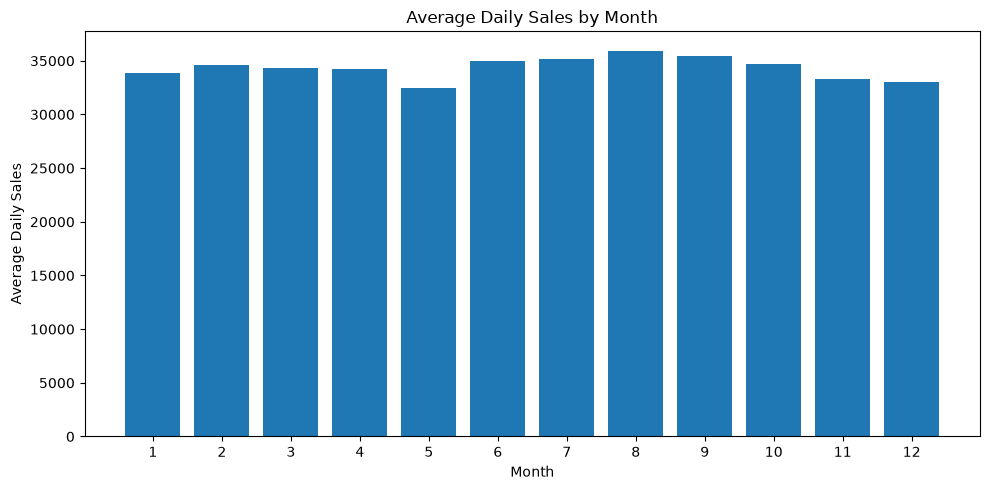

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_pattern.index,
    monthly_pattern.values
)

plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.title("Average Daily Sales by Month")

plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [58]:
daily_trend["weekday"] = daily_trend["date"].dt.day_name()

In [59]:
daily_trend

,d,total_sales,date,month,weekday
0,d_1,32631,2011-01-29,2011-01,Saturday
1,d_2,31749,2011-01-30,2011-01,Sunday
2,d_3,23783,2011-01-31,2011-01,Monday
3,d_4,25412,2011-02-01,2011-02,Tuesday
4,d_5,19146,2011-02-02,2011-02,Wednesday
...,...,...,...,...,...
1908,d_1909,35343,2016-04-20,2016-04,Wednesday
1909,d_1910,35033,2016-04-21,2016-04,Thursday
1910,d_1911,40517,2016-04-22,2016-04,Friday
1911,d_1912,48962,2016-04-23,2016-04,Saturday


In [60]:
weekday_sales = (
    daily_trend
    .groupby("weekday")["total_sales"]
    .mean()
)

print(weekday_sales)



weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

print(weekday_sales)

weekday
Friday       34225.985348
Monday       32852.967033
Saturday     41546.894161
Sunday       41130.021898
Thursday     30205.007326
Tuesday      30368.780220
Wednesday    30010.021978
Name: total_sales, dtype: float64
weekday
Monday       32852.967033
Tuesday      30368.780220
Wednesday    30010.021978
Thursday     30205.007326
Friday       34225.985348
Saturday     41546.894161
Sunday       41130.021898
Name: total_sales, dtype: float64


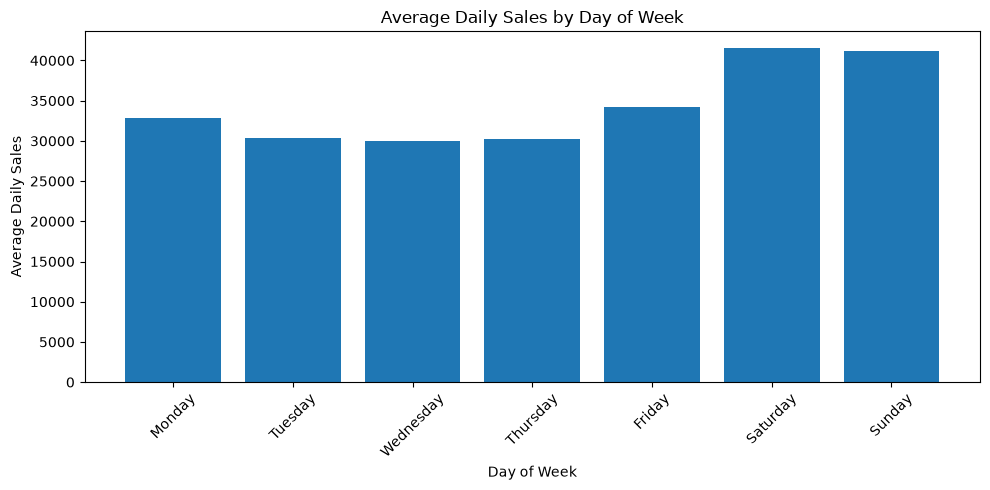

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    weekday_sales.index,
    weekday_sales.values
)

plt.xlabel("Day of Week")
plt.ylabel("Average Daily Sales")
plt.title("Average Daily Sales by Day of Week")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

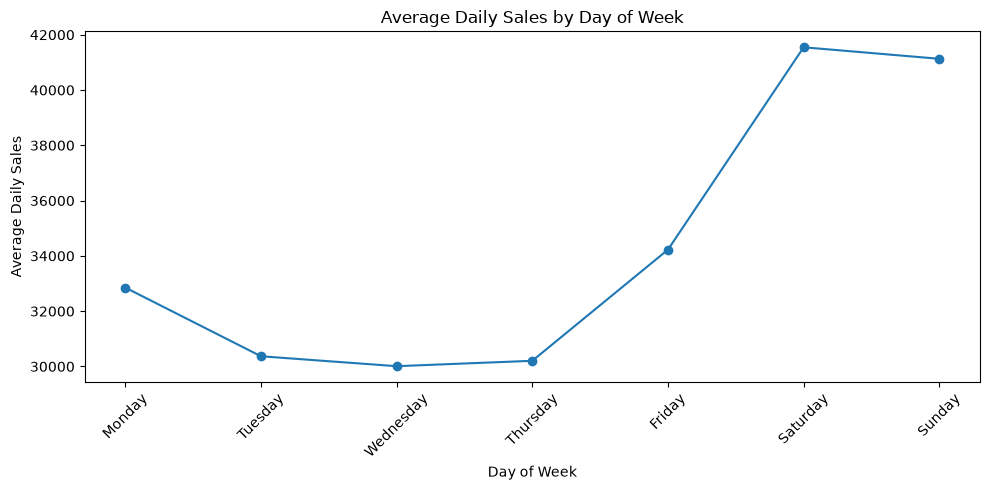

In [62]:
plt.figure(figsize=(10, 5))

plt.plot(
    weekday_sales.index,
    weekday_sales.values,
    marker="o"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Daily Sales")
plt.title("Average Daily Sales by Day of Week")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
print(sales_sample[["id", "store_id", "state_id"]].head())

                              id store_id state_id
0  HOBBIES_1_001_CA_1_validation     CA_1       CA
1  HOBBIES_1_002_CA_1_validation     CA_1       CA
2  HOBBIES_1_003_CA_1_validation     CA_1       CA
3  HOBBIES_1_004_CA_1_validation     CA_1       CA
4  HOBBIES_1_005_CA_1_validation     CA_1       CA


In [64]:
print(sales_ids[["store_id", "state_id"]])

      store_id state_id
0         CA_1       CA
1         CA_1       CA
2         CA_1       CA
3         CA_1       CA
4         CA_1       CA
...        ...      ...
30485     WI_3       WI
30486     WI_3       WI
30487     WI_3       WI
30488     WI_3       WI
30489     WI_3       WI

[30490 rows x 2 columns]


In [65]:
daily_sales

,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8,d_9,d_10,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,0,0,0,0,0,0,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,0,0,0,0,0,0,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,0,0,0,0,0,0,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30485,0,0,2,2,0,3,1,4,1,0,...,2,0,0,0,0,0,1,0,0,1
30486,0,0,0,0,0,5,0,1,1,3,...,0,0,0,0,0,0,0,0,1,0
30487,0,6,0,2,2,4,1,8,5,2,...,2,1,0,2,0,1,0,0,1,0
30488,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,1,0,3,1,3


In [66]:
sales_sample

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


In [67]:
row_total_sales = daily_sales.sum(axis=1)

print(row_total_sales.head())

0     600
1     493
2     288
3    3288
4    1849
dtype: int64


In [68]:
store_sales_data = pd.DataFrame({
    "store_id": sales_ids["store_id"],
    "total_sales": row_total_sales
})

print(store_sales_data.head())

  store_id  total_sales
0     CA_1          600
1     CA_1          493
2     CA_1          288
3     CA_1         3288
4     CA_1         1849


In [69]:
store_sales = (
    store_sales_data
    .groupby("store_id")["total_sales"]
    .sum()
)

print(store_sales)

store_id
CA_1     7698216
CA_2     5685475
CA_3    11188180
CA_4     4103676
TX_1     5595292
TX_2     7214384
TX_3     6089330
WI_1     5149062
WI_2     6544012
WI_3     6427782
Name: total_sales, dtype: int64


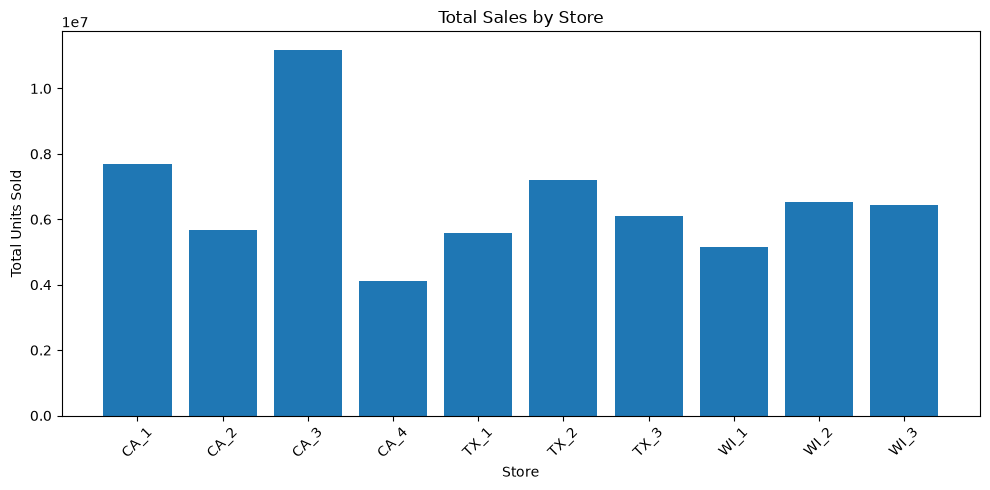

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    store_sales.index,
    store_sales.values
)

plt.xlabel("Store")
plt.ylabel("Total Units Sold")
plt.title("Total Sales by Store")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [71]:
state_sales_data = pd.DataFrame({
    "state_id": sales_ids["state_id"],
    "total_sales": row_total_sales
})

print(state_sales_data.head())

  state_id  total_sales
0       CA          600
1       CA          493
2       CA          288
3       CA         3288
4       CA         1849


In [72]:
state_sales = (
    state_sales_data
    .groupby("state_id")["total_sales"]
    .sum()
)

print(state_sales)

state_id
CA    28675547
TX    18899006
WI    18120856
Name: total_sales, dtype: int64


In [73]:
category_sales_data = pd.DataFrame({
    "cat_id": sales_ids["cat_id"],
    "total_sales": row_total_sales
})

print(category_sales_data.head())

    cat_id  total_sales
0  HOBBIES          600
1  HOBBIES          493
2  HOBBIES          288
3  HOBBIES         3288
4  HOBBIES         1849


In [74]:
category_sales = (
    category_sales_data
    .groupby("cat_id")["total_sales"]
    .sum()
)

print(category_sales)

cat_id
FOODS        45089939
HOBBIES       6124800
HOUSEHOLD    14480670
Name: total_sales, dtype: int64


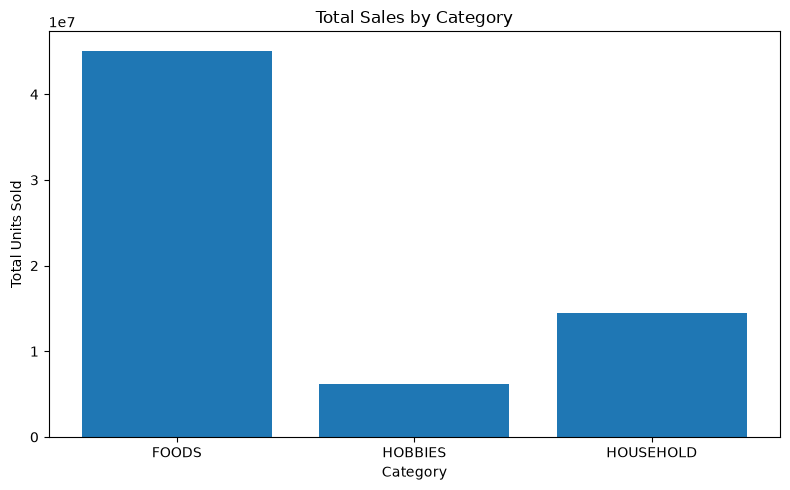

In [75]:
plt.figure(figsize=(8, 5))

plt.bar(category_sales.index, category_sales.values)

plt.xlabel("Category")
plt.ylabel("Total Units Sold")
plt.title("Total Sales by Category")

plt.tight_layout()
plt.show()

In [76]:
dept_sales_data = pd.DataFrame({
    "dept_id": sales_ids["dept_id"],
    "total_sales": row_total_sales
})

print(dept_sales_data.head())

     dept_id  total_sales
0  HOBBIES_1          600
1  HOBBIES_1          493
2  HOBBIES_1          288
3  HOBBIES_1         3288
4  HOBBIES_1         1849


In [77]:
dept_sales = (
    dept_sales_data
    .groupby("dept_id")["total_sales"]
    .sum()
)

print(dept_sales)

dept_id
FOODS_1         5088041
FOODS_2         7629822
FOODS_3        32372076
HOBBIES_1       5596460
HOBBIES_2        528340
HOUSEHOLD_1    11500526
HOUSEHOLD_2     2980144
Name: total_sales, dtype: int64


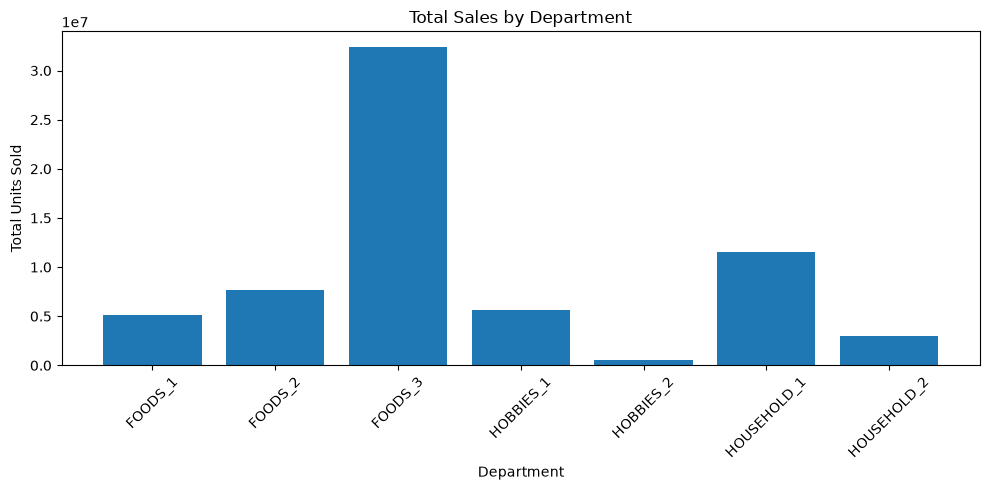

In [78]:
plt.figure(figsize=(10, 5))

plt.bar(dept_sales.index, dept_sales.values)

plt.xlabel("Department")
plt.ylabel("Total Units Sold")
plt.title("Total Sales by Department")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [79]:
product_sales_data = pd.DataFrame({})

In [80]:
sales_ids

,item_id,dept_id,cat_id,store_id,state_id
0,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA
1,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA
2,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA
3,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA
4,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA
...,...,...,...,...,...
30485,FOODS_3_823,FOODS_3,FOODS,WI_3,WI
30486,FOODS_3_824,FOODS_3,FOODS,WI_3,WI
30487,FOODS_3_825,FOODS_3,FOODS,WI_3,WI
30488,FOODS_3_826,FOODS_3,FOODS,WI_3,WI


In [81]:

product_sales_data = pd.DataFrame({"item_id":sales_ids["item_id"],
                        "total_sales":row_total_sales})




In [82]:
product_sales = (
    product_sales_data
    .groupby("item_id")["total_sales"]
    .sum()
)

print(product_sales)

item_id
FOODS_1_001         12247
FOODS_1_002          7334
FOODS_1_003         13394
FOODS_1_004        129481
FOODS_1_005         22914
                    ...  
HOUSEHOLD_2_512     11555
HOUSEHOLD_2_513      7916
HOUSEHOLD_2_514      3150
HOUSEHOLD_2_515      1121
HOUSEHOLD_2_516      2543
Name: total_sales, Length: 3049, dtype: int64


In [83]:
top_products = product_sales.sort_values(ascending=False).head(10)

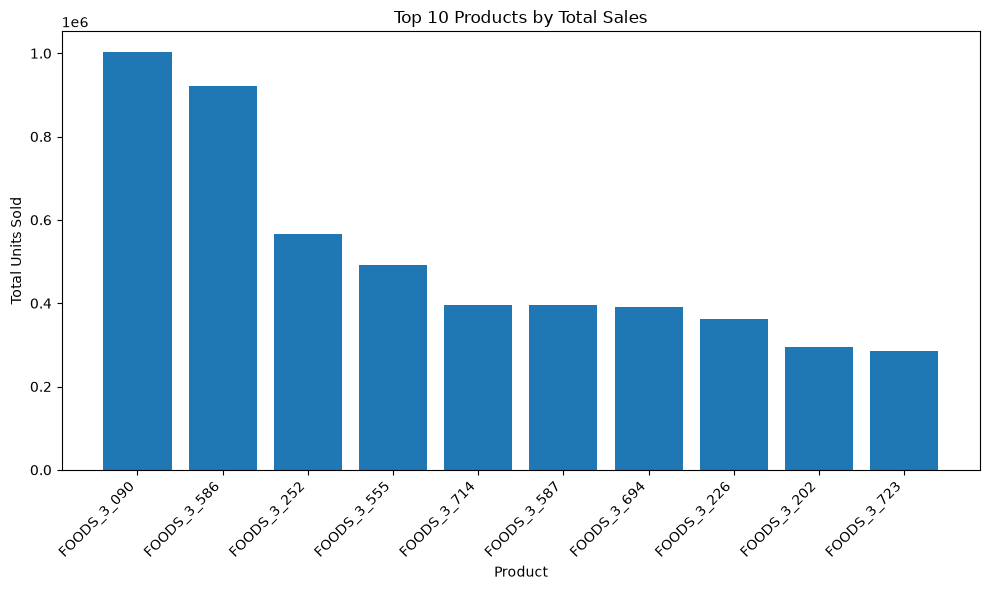

In [84]:
plt.figure(figsize=(10, 6))

plt.bar(top_products.index, top_products.values)

plt.xlabel("Product")
plt.ylabel("Total Units Sold")
plt.title("Top 10 Products by Total Sales")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [85]:
state_category_data = pd.DataFrame({
    "state_id": sales_ids["state_id"],
    "cat_id": sales_ids["cat_id"],
    "total_sales": row_total_sales
})

print(state_category_data.head())




  state_id   cat_id  total_sales
0       CA  HOBBIES          600
1       CA  HOBBIES          493
2       CA  HOBBIES          288
3       CA  HOBBIES         3288
4       CA  HOBBIES         1849


In [86]:

state_category_sales = (
    state_category_data
    .groupby(["state_id", "cat_id"])["total_sales"]
    .sum()
    
)

print(state_category_sales)

state_id  cat_id   
CA        FOODS        19196302
          HOBBIES       3039883
          HOUSEHOLD     6439362
TX        FOODS        12956421
          HOBBIES       1592339
          HOUSEHOLD     4350246
WI        FOODS        12937216
          HOBBIES       1492578
          HOUSEHOLD     3691062
Name: total_sales, dtype: int64


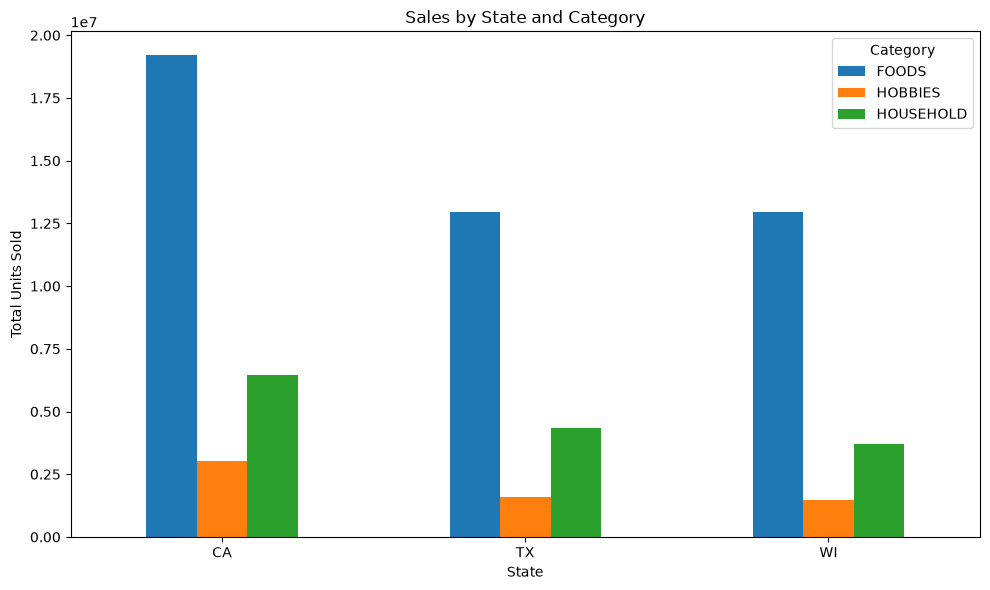

In [87]:
state_category_plot = state_category_sales.unstack()

state_category_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("State")
plt.ylabel("Total Units Sold")
plt.title("Sales by State and Category")

plt.xticks(rotation=0)
plt.legend(title="Category")

plt.tight_layout()
plt.show()

In [88]:
state_category_plot

cat_id,FOODS,HOBBIES,HOUSEHOLD
state_id,,,
CA,19196302,3039883,6439362
TX,12956421,1592339,4350246
WI,12937216,1492578,3691062


store-category data


In [89]:
category_store_sales = pd.DataFrame({
    "cat_id":sales_ids["cat_id"],
    "store_id":sales_ids["store_id"],
    "total_sales":row_total_sales
})

category_store_sales.head()

,cat_id,store_id,total_sales
0,HOBBIES,CA_1,600
1,HOBBIES,CA_1,493
2,HOBBIES,CA_1,288
3,HOBBIES,CA_1,3288
4,HOBBIES,CA_1,1849


In [90]:
category_store_sales_grouped = (
    category_store_sales.groupby(["cat_id", "store_id"])["total_sales"]
    .sum()  )

category_store_sales_grouped

cat_id     store_id
FOODS      CA_1        5380828
           CA_2        3480259
           CA_3        7515790
           CA_4        2819425
           TX_1        3778209
           TX_2        5015124
           TX_3        4163088
           WI_1        3438352
           WI_2        4768184
           WI_3        4730680
HOBBIES    CA_1         876678
           CA_2         637803
           CA_3         960947
           CA_4         564455
           TX_1         429084
           TX_2         635997
           TX_3         527258
           WI_1         655696
           WI_2         370214
           WI_3         466668
HOUSEHOLD  CA_1        1440710
           CA_2        1567413
           CA_3        2711443
           CA_4         719796
           TX_1        1387999
           TX_2        1563263
           TX_3        1398984
           WI_1        1055014
           WI_2        1405614
           WI_3        1230434
Name: total_sales, dtype: int64

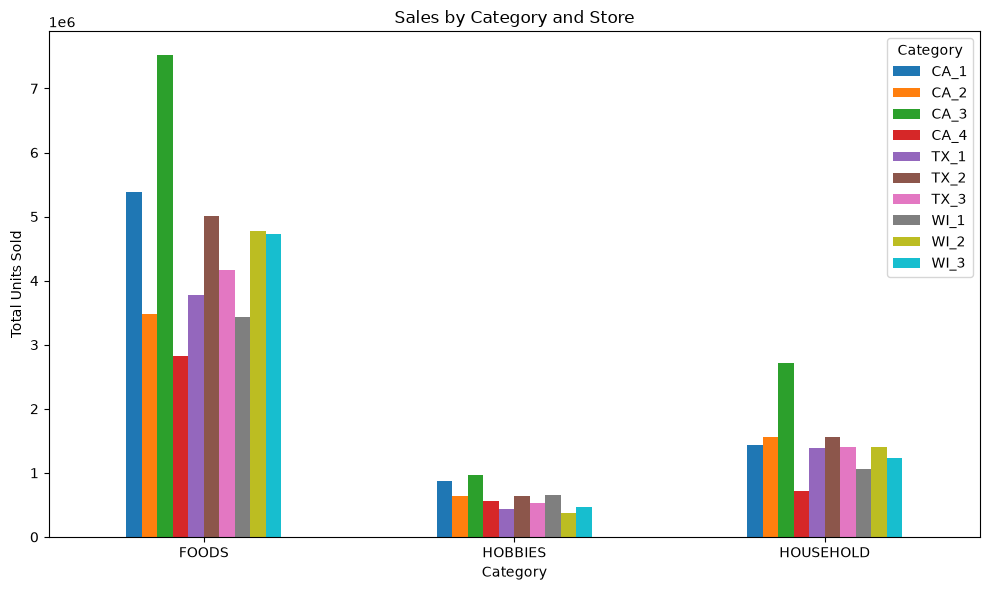

In [91]:
cate_store_plot = category_store_sales_grouped.unstack()

cate_store_plot.plot(
    kind="bar",
    figsize=(10, 6)
)   
plt.xlabel("Category")
plt.ylabel("Total Units Sold")
plt.title("Sales by Category and Store")

plt.xticks(rotation=0)
plt.legend(title="Category")

plt.tight_layout()
plt.show()


In [92]:
daily_trend = daily_trend.merge(
    calendar_df[
        ["d", "event_name_1", "event_type_1",
         "event_name_2", "event_type_2"]
    ],
    on="d",
    how="left"
)

daily_trend["is_event_day"] = (
    daily_trend["event_name_1"].notna() |
    daily_trend["event_name_2"].notna()
)

print(daily_trend[["date", "total_sales", "event_name_1", "is_event_day"]].head())

        date  total_sales event_name_1  is_event_day
0 2011-01-29        32631          NaN         False
1 2011-01-30        31749          NaN         False
2 2011-01-31        23783          NaN         False
3 2011-02-01        25412          NaN         False
4 2011-02-02        19146          NaN         False


In [93]:
event_sales = (
    daily_trend
    .groupby("is_event_day")["total_sales"]
    .mean()
)

print(event_sales)

is_event_day
False    34489.207504
True     32655.149351
Name: total_sales, dtype: float64


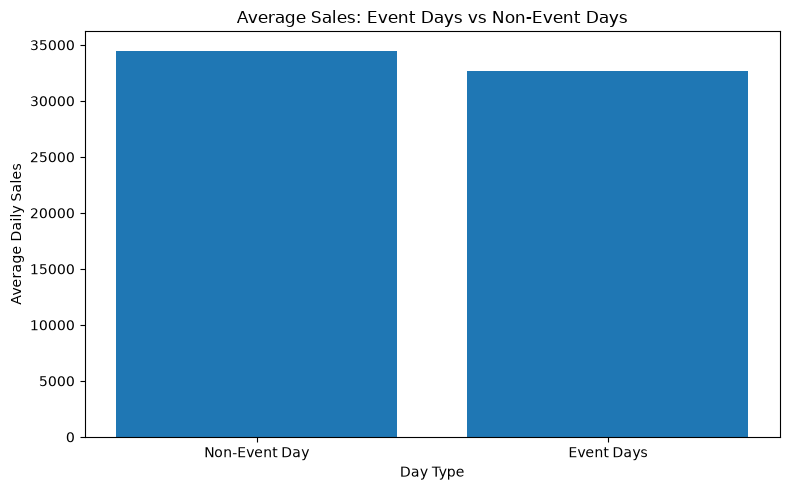

In [94]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Non-Event Day", "Event Days"],
    event_sales.values
)

plt.xlabel("Day Type")
plt.ylabel("Average Daily Sales")
plt.title("Average Sales: Event Days vs Non-Event Days")

plt.tight_layout()
plt.show()

In [95]:
event_day_sales = (
    daily_trend[daily_trend["event_name_1"].notna()]
    .groupby("event_name_1")["total_sales"]
    .mean()
    .sort_values(ascending=False)
)

print(event_day_sales)

event_name_1
LaborDay               42154.600000
SuperBowl              40924.000000
Easter                 39517.600000
OrthodoxEaster         38277.000000
Father's day           36562.000000
Purim End              35957.000000
Eid al-Fitr            35267.600000
ColumbusDay            35164.800000
VeteransDay            35118.800000
Ramadan starts         34779.600000
EidAlAdha              34504.000000
PresidentsDay          34446.333333
Mother's day           34211.400000
IndependenceDay        33710.800000
NBAFinalsEnd           33564.200000
ValentinesDay          33495.666667
StPatricksDay          33459.666667
Pesach End             33450.200000
Chanukah End           33426.800000
MartinLutherKingDay    33378.600000
OrthodoxChristmas      33344.200000
Cinco De Mayo          32823.500000
MemorialDay            32699.600000
NBAFinalsStart         31874.400000
LentStart              30727.000000
Halloween              30059.400000
LentWeek2              29747.000000
NewYear        

In [99]:
daily_trend

,d,total_sales,date,month,weekday,event_name_1,event_type_1,event_name_2,event_type_2,is_event_day,rolling_mean_7,rolling_mean_28
0,d_1,32631,2011-01-29,2011-01,Saturday,NaN,NaN,NaN,NaN,False,NaN,NaN
1,d_2,31749,2011-01-30,2011-01,Sunday,NaN,NaN,NaN,NaN,False,NaN,NaN
2,d_3,23783,2011-01-31,2011-01,Monday,NaN,NaN,NaN,NaN,False,NaN,NaN
3,d_4,25412,2011-02-01,2011-02,Tuesday,NaN,NaN,NaN,NaN,False,NaN,NaN
4,d_5,19146,2011-02-02,2011-02,Wednesday,NaN,NaN,NaN,NaN,False,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
1908,d_1909,35343,2016-04-20,2016-04,Wednesday,NaN,NaN,NaN,NaN,False,41448.857143,42449.964286
1909,d_1910,35033,2016-04-21,2016-04,Thursday,NaN,NaN,NaN,NaN,False,41470.285714,42469.857143
1910,d_1911,40517,2016-04-22,2016-04,Friday,NaN,NaN,NaN,NaN,False,41113.714286,42506.642857
1911,d_1912,48962,2016-04-23,2016-04,Saturday,NaN,NaN,NaN,NaN,False,40932.000000,42324.714286


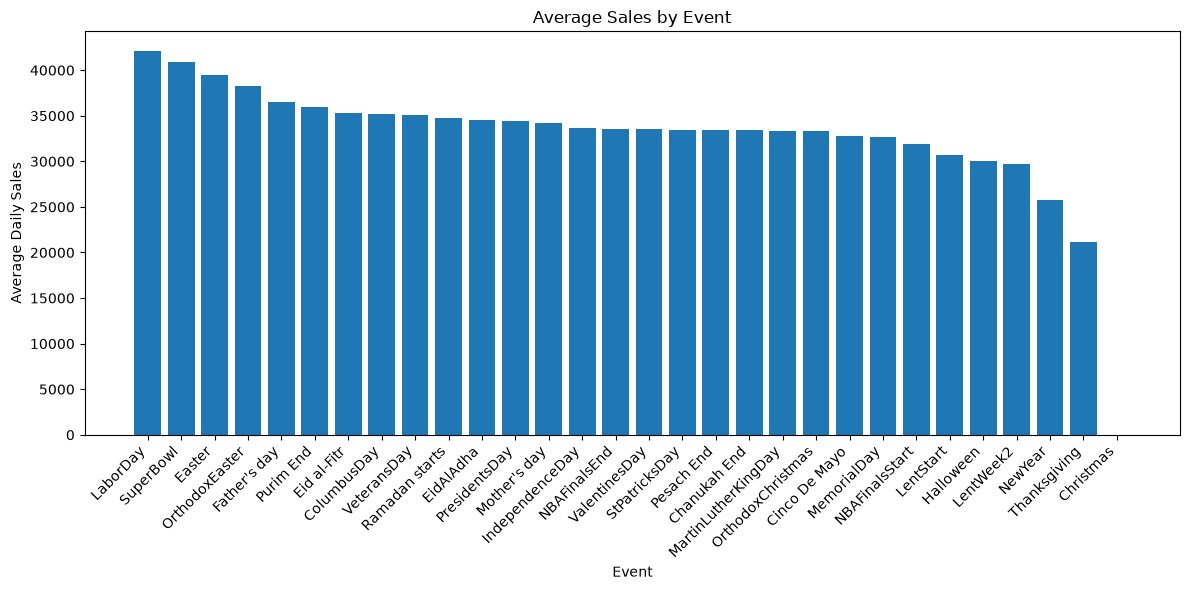

In [96]:
plt.figure(figsize=(12, 6))

plt.bar(
    event_day_sales.index,
    event_day_sales.values
)

plt.xlabel("Event")
plt.ylabel("Average Daily Sales")
plt.title("Average Sales by Event")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [103]:
daily_trend["year"] = daily_trend["date"].dt.year
daily_trend["day"] = daily_trend["date"].dt.day
daily_trend["day_of_week"] = daily_trend["date"].dt.dayofweek

print(
    daily_trend[
        ["date", "year", "month", "day", "day_of_week", "weekday"]
    ].head(10)
)

daily_trend["week_of_year"] = (
    daily_trend["date"].dt.isocalendar().week.astype(int)
)

print(daily_trend[["date", "week_of_year"]].head(10))

        date  year    month  day  day_of_week    weekday
0 2011-01-29  2011  2011-01   29            5   Saturday
1 2011-01-30  2011  2011-01   30            6     Sunday
2 2011-01-31  2011  2011-01   31            0     Monday
3 2011-02-01  2011  2011-02    1            1    Tuesday
4 2011-02-02  2011  2011-02    2            2  Wednesday
5 2011-02-03  2011  2011-02    3            3   Thursday
6 2011-02-04  2011  2011-02    4            4     Friday
7 2011-02-05  2011  2011-02    5            5   Saturday
8 2011-02-06  2011  2011-02    6            6     Sunday
9 2011-02-07  2011  2011-02    7            0     Monday
        date  week_of_year
0 2011-01-29             4
1 2011-01-30             4
2 2011-01-31             5
3 2011-02-01             5
4 2011-02-02             5
5 2011-02-03             5
6 2011-02-04             5
7 2011-02-05             5
8 2011-02-06             5
9 2011-02-07             6


In [104]:
features = [
    "year",
    "month",
    "day",
    "day_of_week",
    "week_of_year"
]

X = daily_trend[features]
y = daily_trend["total_sales"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

X shape: (1913, 5)
y shape: (1913,)
   year    month  day  day_of_week  week_of_year
0  2011  2011-01   29            5             4
1  2011  2011-01   30            6             4
2  2011  2011-01   31            0             5
3  2011  2011-02    1            1             5
4  2011  2011-02    2            2             5


In [106]:
train_mask = daily_trend["date"] < "2015-01-01"
validation_mask = (
    (daily_trend["date"] >= "2015-01-01") &
    (daily_trend["date"] < "2016-01-01")
)

test_mask = daily_trend["date"] >= "2016-01-01"


In [109]:
X[train_mask]

,year,month,day,day_of_week,week_of_year
0,2011,2011-01,29,5,4
1,2011,2011-01,30,6,4
2,2011,2011-01,31,0,5
3,2011,2011-02,1,1,5
4,2011,2011-02,2,2,5
...,...,...,...,...,...
1428,2014,2014-12,27,5,52
1429,2014,2014-12,28,6,52
1430,2014,2014-12,29,0,1
1431,2014,2014-12,30,1,1


In [110]:
X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[validation_mask]
y_val = y[validation_mask]

X_test = X[test_mask]
y_test = y[test_mask]


print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (1433, 5)
Validation: (365, 5)
Test: (115, 5)
